# Modern Portfolio Theory: Mathematical Optimization of Risk and Return Using Python

**Project status:** Part 1 — problem formulation, data exploration, mathematical foundations, and the equal-weight benchmark.

**Research question:** *How can the allocation of capital across four technology stocks affect expected return and volatility, and can mathematical optimization improve on a simple equal-weight allocation?*

**Scope:** Long-only portfolios of four assets (AAPL, MSFT, GOOG, AMZN); fully invested weights summing to one; weekly simple returns; annualized sample moments. Later sections will estimate weights on the training period and test them out of sample.

**Important:** This is a mathematical case study, not investment advice or a claim that historical patterns predict future performance.

## 1. Objectives and scientific approach

1. State the portfolio allocation problem in mathematical terms.
2. Describe and validate the historical sample dataset.
3. Calculate weekly returns, correlations, annualized arithmetic mean returns, and annualized covariance.
4. Implement and test formulas for portfolio expected return and volatility.
5. **Next iteration:** compare Monte Carlo allocations with constrained minimum-variance and maximum-Sharpe portfolios, then evaluate on held-out data.

**Hypothesis to test later:** An optimized portfolio can exhibit lower *estimated in-sample variance* than an equal-weight portfolio. Whether that advantage persists on unseen observations is an empirical question, not a guarantee.

## 2. Data and reproducibility

We use the **Plotly sample stocks dataset** (six technology stocks, 2018–2019). The local CSV is an extracted subset of the four selected companies. The series are *normalized price indices* starting at 1, **not** USD price quotes. Percent changes of a normalized index are suitable for this exercise.

**Source:** [Plotly data documentation](https://plotly.com/python-api-reference/generated/plotly.data.html) — `plotly.data.stocks()` (also available as `plotly.express.data.stocks()`).

**Limitations:** The dataset covers a short and dated interval, consists entirely of technology stocks, and does not document whether the indices include cash dividends, transactions costs, or other real-market frictions. We therefore analyze *sample price-index returns*, not actual total investor returns.

The CSV is included with this repository; rerunning the notebook requires **no internet connection**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 5), "axes.grid": True, "grid.alpha": 0.25})

DATA_PATH = Path("data/stocks_normalized_2018_2019.csv")
ASSETS = ["AAPL", "MSFT", "GOOG", "AMZN"]
WEEKS_PER_YEAR = 52

In [2]:
prices = pd.read_csv(DATA_PATH, parse_dates=["date"]).set_index("date")
prices = prices[ASSETS].sort_index()

# Explicit checks keep the analysis reproducible and fail early on bad data.
assert not prices.empty
assert prices.index.is_unique and prices.index.is_monotonic_increasing
assert not prices.isna().any().any()
assert (prices > 0).all().all()
assert prices.shape[0] >= 100

print(f"Observations: {len(prices)}")
print(f"From: {prices.index.min().date()} to {prices.index.max().date()}")
display(prices.head())

Observations: 105
From: 2018-01-01 to 2019-12-30


,AAPL,MSFT,GOOG,AMZN
date,,,,
2018-01-01,1.000000,1.000000,1.000000,1.000000
2018-01-08,1.011943,1.015988,1.018172,1.061881
2018-01-15,1.019771,1.020524,1.032008,1.053240
2018-01-22,0.980057,1.066561,1.066783,1.140676
2018-01-29,0.917143,1.040708,1.008773,1.163374


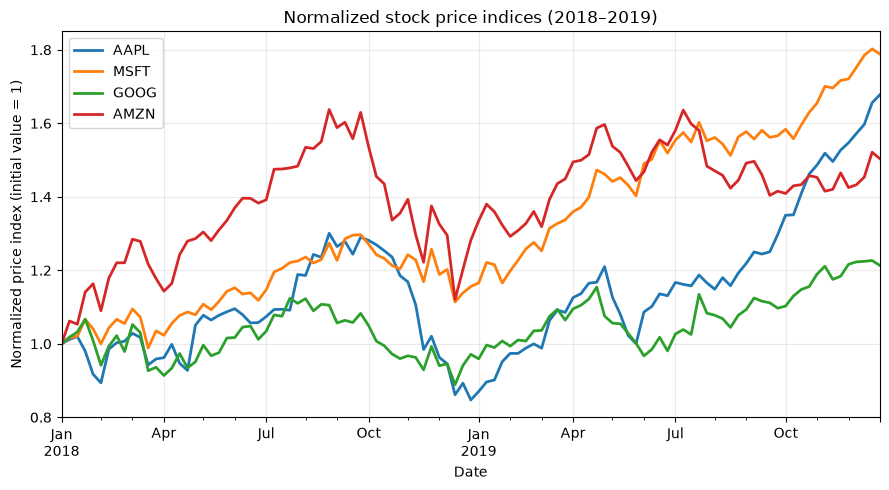

In [3]:
ax = prices.plot(linewidth=2, title="Normalized stock price indices (2018–2019)")
ax.set_ylabel("Normalized price index (initial value = 1)")
ax.set_xlabel("Date")
plt.tight_layout()
plt.show()

## 3. Mathematical background

Let $P_{i,t}$ be the normalized index value for stock $i$ at week $t$. Its **weekly simple return** is

$$r_{i,t}=\frac{P_{i,t}}{P_{i,t-1}}-1.$$

For $n=4$ assets, the portfolio weight vector is $\mathbf{w}=(w_1,\dots,w_4)^T$ with long-only, fully invested constraints

$$\sum_{i=1}^4 w_i=1, \qquad 0\le w_i\le 1.$$

The estimated **annualized arithmetic expected return** and **annualized covariance matrix** are

$$\boldsymbol{\hat\mu}_{ann}=52\,\overline{\mathbf r}_{weekly}, \qquad \hat\Sigma_{ann}=52\,\widehat{\mathrm{Cov}}(\mathbf r_{weekly}).$$

The corresponding estimated portfolio expected return and volatility are

$$\hat\mu_p=\mathbf w^T\boldsymbol{\hat\mu}_{ann}, \qquad
\hat\sigma_p=\sqrt{\mathbf w^T\hat\Sigma_{ann}\mathbf w}.$$

The square-root in the final expression converts **variance** into **standard deviation**. This is the mean-variance portfolio framework discussed by Markowitz (1952). For weekly observations, the factor of 52 is an approximation based on stationarity and standard aggregation assumptions. Annualized arithmetic mean return is **not** the same as realized compounded annual return.

In [4]:
weekly_returns = prices.pct_change().dropna()
assert len(weekly_returns) == len(prices) - 1
assert np.isfinite(weekly_returns.to_numpy()).all()

# Chronological split: reserve the last 30% for later out-of-sample evaluation.
split_at = int(len(weekly_returns) * 0.70)
train_returns = weekly_returns.iloc[:split_at].copy()
test_returns = weekly_returns.iloc[split_at:].copy()
assert train_returns.index.max() < test_returns.index.min()

annual_mean = train_returns.mean() * WEEKS_PER_YEAR
annual_cov = train_returns.cov() * WEEKS_PER_YEAR
annual_volatility = train_returns.std(ddof=1) * np.sqrt(WEEKS_PER_YEAR)

summary = pd.DataFrame({
    "Annualized arithmetic mean": annual_mean,
    "Annualized volatility": annual_volatility,
})
print(f"Training weeks: {len(train_returns)}; held-out weeks: {len(test_returns)}")
display(summary.style.format("{:.2%}"))

Training weeks: 72; held-out weeks: 32


,Annualized arithmetic mean,Annualized volatility
AAPL,6.05%,30.03%
MSFT,28.15%,21.00%
GOOG,5.10%,24.89%
AMZN,33.22%,30.72%


## 4. Diversification and covariance

Diversification is not solely about the number of assets; it depends on how their returns co-move. Correlation near +1 implies limited diversification benefit, while lower correlations can reduce portfolio variance for a fixed set of weights. These four technology companies are not a broad representation of the market.

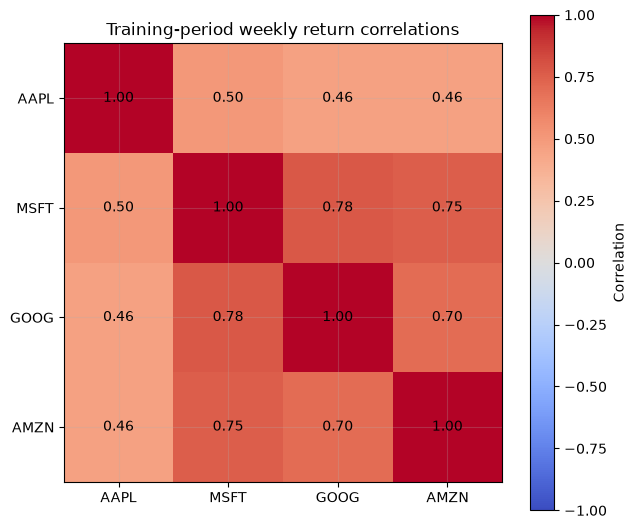

In [5]:
correlation = train_returns.corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(correlation.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(ASSETS)), ASSETS)
ax.set_yticks(range(len(ASSETS)), ASSETS)
for i in range(len(ASSETS)):
    for j in range(len(ASSETS)):
        ax.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Training-period weekly return correlations")
fig.tight_layout()
plt.show()

## 5. Equal-weight benchmark and validation

A neutral baseline assigns 25% to each of the four assets. It is **not** necessarily the lowest-risk or highest-return allocation. Implementing the formulas from Section 3 provides a testable benchmark for later numerical optimization.

In [6]:
def portfolio_statistics(weights: np.ndarray,
                         expected_returns: pd.Series,
                         covariance: pd.DataFrame) -> tuple[float, float]:
    """Return annualized arithmetic expected return and volatility.

    Parameters
    ----------
    weights : array of shape (n_assets,)
        Non-negative portfolio fractions summing to one.
    expected_returns : Series
        Estimated annualized arithmetic asset returns.
    covariance : DataFrame
        Estimated annualized asset return covariance matrix.
    """
    w = np.asarray(weights, dtype=float)
    mu = expected_returns.to_numpy(dtype=float)
    sigma = covariance.to_numpy(dtype=float)
    if w.ndim != 1 or w.size != len(mu) or sigma.shape != (w.size, w.size):
        raise ValueError("Incompatible vector or covariance dimensions")
    if not np.isclose(w.sum(), 1.0, atol=1e-8) or np.any(w < -1e-10):
        raise ValueError("Weights must be non-negative and sum to 1")

    expected_return = float(w @ mu)
    variance = float(w @ sigma @ w)
    volatility = float(np.sqrt(max(variance, 0.0)))  # protect against rounding
    return expected_return, volatility


weights_equal = np.full(len(ASSETS), 1 / len(ASSETS))
equal_return, equal_volatility = portfolio_statistics(weights_equal, annual_mean, annual_cov)
print("Equal-weight allocation:", dict(zip(ASSETS, weights_equal)))
print(f"Estimated annualized arithmetic return: {equal_return:.2%}")
print(f"Estimated annualized volatility:       {equal_volatility:.2%}")

Equal-weight allocation: {'AAPL': np.float64(0.25), 'MSFT': np.float64(0.25), 'GOOG': np.float64(0.25), 'AMZN': np.float64(0.25)}
Estimated annualized arithmetic return: 18.13%
Estimated annualized volatility:       22.25%


In [7]:
# Mathematical checks: a 100% allocation to one asset must reproduce
# that asset's expected return and volatility.
for i, asset in enumerate(ASSETS):
    single_asset_weights = np.eye(len(ASSETS))[i]
    r, v = portfolio_statistics(single_asset_weights, annual_mean, annual_cov)
    assert np.isclose(r, annual_mean[asset], rtol=1e-10)
    assert np.isclose(v, annual_volatility[asset], rtol=1e-10)

assert np.allclose(annual_cov, annual_cov.T)
assert np.linalg.eigvalsh(annual_cov.to_numpy()).min() > -1e-10
print("All portfolio formula checks passed.")

All portfolio formula checks passed.


## 6. Preliminary interpretation and next steps

**What has been established:**

- The raw price indices, return calculations, and covariance matrix are reproducible using local data.
- The mean–variance formulas agree with directly observed single-asset estimates in validation tests.
- The equal-weight portfolio supplies a transparent comparison point for optimization.

**Not yet established:** We have **not** shown that optimization outperforms the benchmark, either in the training set or the held-out period. The next implementation stage will add:

1. 5,000 random long-only portfolios generated with a fixed random seed.
2. Constrained *minimum-variance* optimization via SciPy SLSQP.
3. Maximum *Sharpe-ratio* optimization (using an explicitly assumed risk-free rate).
4. A risk–return plot and comparison against equal weights.
5. Held-out testing with frozen weights, plus sensitivity checks and limitations.

**Limitations worth testing:** estimation error in expected returns, a short sample period, concentration in one sector, nonstationarity, omission of dividends, transactions costs and taxes, and the assumption of periodic rebalancing.

## References

1. Markowitz, H. (1952). *Portfolio Selection*. *The Journal of Finance*, 7(1), 77–91. https://doi.org/10.1111/j.1540-6261.1952.tb01525.x
2. Plotly. *plotly.data.stocks* documentation (sample closing price indices for six tech stocks, 2018–2019): https://plotly.com/python-api-reference/generated/plotly.data.html
3. SciPy. *minimize(method='SLSQP')* documentation: https://docs.scipy.org/doc/scipy/reference/optimize.minimize-slsqp.html